[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L7/BA_L7_csad/BA_L7_csad.ipynb)

# BA_L7_csad: Herding in crypto: the CSAD test

*Quantlet of Lecture 7, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Herding test of Chang, Cheng and Khorana (2000) on 19 cryptocurrencies: cross-sectional absolute deviation (CSAD) regressed on the absolute and squared equal-weighted market return with HAC(10) errors, full sample and rolling 365-day windows (EODHD daily log returns, January 2021 - October 2026).

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
from scipy import stats
import statsmodels.api as sm

END = '2026-10-23'                      # last day of the lecture sample
plt.rcParams.update({'font.size': 10})  # as in the slide charts


def px(sym):
    """Daily price of one EODHD symbol to END; dividend- and split-adjusted close for US stocks and funds."""
    d = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    s = d['adjusted_close'] if sym.endswith('.US') else d['close']
    return s[s > 0].loc[:END]


def slide_fig(fig, name, bottom, ncol=3):
    """Legend of all axes below the plot (as in the slides), then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

### Data

Daily closes of 19 coins from EODHD (course repository, `data/market`), 1 January 2021 to 23 October 2026.
Returns are daily log returns in per cent, $r_t = 100\,(\ln P_t - \ln P_{t-1})$.

In [5]:
COINS = ['BTC', 'ETH', 'XRP', 'BNB', 'SOL', 'ADA', 'DOGE', 'TRX', 'LTC', 'BCH', 'LINK', 'XLM', 'DOT', 'AVAX', 'ATOM', 'XMR', 'ETC', 'FIL', 'ALGO']
P = pd.DataFrame({c: px(f'{c}-USD.CC') for c in COINS}).loc['2021-01-01':]
R = (100 * np.log(P).diff()).dropna()           # daily log returns in %
print(f'Crypto panel: {R.shape[1]} coins, {R.shape[0]} days of daily log returns, {R.index[0].date()} to {R.index[-1].date()}')

Crypto panel: 19 coins, 2121 days of daily log returns, 2021-01-02 to 2026-10-23


### Method

The cross-sectional absolute deviation (CSAD) measures how far coin returns spread around the market return $R_{m,t}$ (the equal-weighted
mean of the 19 coins): $\mathrm{CSAD}_t = \frac1N\sum_{i=1}^N |R_{i,t} - R_{m,t}|$. Under rational pricing (the capital asset pricing model, CAPM)
dispersion rises linearly with $|R_{m,t}|$; under herding it rises *less* in large moves. Chang, Cheng and Khorana (2000) estimate

$$ \mathrm{CSAD}_t = \alpha + \gamma_1 |R_{m,t}| + \gamma_2 R_{m,t}^2 + \varepsilon_t, \qquad H_0: \gamma_2 = 0, \quad \text{herding: } \gamma_2 < 0, $$

with heteroskedasticity and autocorrelation consistent (HAC) standard errors, 10 lags; on all days, up days, down days, and on rolling
365-day windows moved forward 15 days at a time.

In [6]:
Rm = R.mean(axis=1)
csad = R.sub(Rm, axis=0).abs().mean(axis=1)
X = sm.add_constant(pd.DataFrame({'absRm': Rm.abs(), 'Rm2': Rm ** 2}))
hac = dict(cov_type='HAC', cov_kwds={'maxlags': 10})
fits = {'all days': sm.OLS(csad, X).fit(**hac),
        'up days (R_m > 0)': sm.OLS(csad[Rm > 0], X[Rm > 0]).fit(**hac),
        'down days (R_m <= 0)': sm.OLS(csad[Rm <= 0], X[Rm <= 0]).fit(**hac)}
print(pd.DataFrame({k: {'gamma_1': m.params['absRm'], 't(gamma_1)': m.tvalues['absRm'], 'gamma_2': m.params['Rm2'],
                        't(gamma_2)': m.tvalues['Rm2'], 'R2': m.rsquared, 'days': int(m.nobs)}
                    for k, m in fits.items()}).T.round(4).to_string())
h = fits['all days']
print(f"\nVertex of the fitted curve: |R_m| = gamma_1 / (2 |gamma_2|) = {h.params['absRm'] / (2 * abs(h.params['Rm2'])):.0f}%")
print(f'Days with |R_m| > 15%: {(Rm.abs() > 15).sum()}')

rg = {}
for k in range(365, len(R) + 1, 15):
    sl = slice(k - 365, k)
    m = sm.OLS(csad.iloc[sl], X.iloc[sl]).fit(**hac)
    rg[R.index[k - 1]] = (m.params['Rm2'], m.tvalues['Rm2'])
rg = pd.DataFrame(rg, index=['g2', 't']).T
print(f"Rolling 365-day windows: gamma_2 significantly negative (t < -1.96) in {100 * (rg['t'] < -1.96).mean():.1f}% of windows, "
      f"significantly positive (t > 1.96) in {100 * (rg['t'] > 1.96).mean():.1f}%")

                      gamma_1  t(gamma_1)  gamma_2  t(gamma_2)      R2    days
all days               0.2542     10.7584  -0.0028     -2.8838  0.2476  2121.0
up days (R_m > 0)      0.3179      4.4155   0.0003      0.0340  0.3013  1122.0
down days (R_m <= 0)   0.1511      6.9721  -0.0001     -0.1205  0.2576   999.0

Vertex of the fitted curve: |R_m| = gamma_1 / (2 |gamma_2|) = 45%
Days with |R_m| > 15%: 16
Rolling 365-day windows: gamma_2 significantly negative (t < -1.96) in 1.7% of windows, significantly positive (t > 1.96) in 39.0%


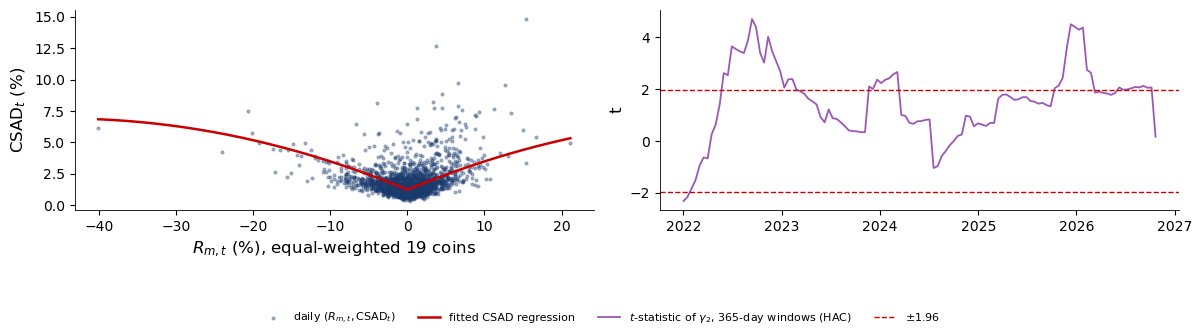

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].scatter(Rm, csad, s=4, color=BLUE, alpha=0.35, label=r'daily $(R_{m,t}, \mathrm{CSAD}_t)$')
xx = np.linspace(Rm.min(), Rm.max(), 300)
ax[0].plot(xx, h.params['const'] + h.params['absRm'] * np.abs(xx) + h.params['Rm2'] * xx ** 2, color=RED, lw=1.8, label='fitted CSAD regression')
ax[0].set_xlabel(r'$R_{m,t}$ (%), equal-weighted 19 coins'); ax[0].set_ylabel(r'CSAD$_t$ (%)')
ax[1].plot(rg.index, rg['t'], color=ETH, lw=1.3, label=r'$t$-statistic of $\gamma_2$, 365-day windows (HAC)')
ax[1].axhline(-1.96, color=RED, ls='--', lw=1, label=r'$\pm 1.96$'); ax[1].axhline(1.96, color=RED, ls='--', lw=1)
ax[1].set_ylabel('t')
slide_fig(fig, 'ba_l7_csad', 0.17, ncol=4)

**How to read it.** Over the full sample $\hat\gamma_2 < 0$ is significant, but the curvature rests on a few days of extreme market moves.
In rolling windows $\gamma_2$ is rarely significantly negative and often significantly positive: herding is an episode, not a trait.